# __Amazon Books Dataset - Eksploracyjna analiza danych (EDA)__ 📚
---
## __1. Wprowadzenie__
W projekcie wykorzystano zbiór danych [__Amazon Books Reviews__](https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews/), zawierający informacje o książkach dostępnych na platformie Amazon oraz recenzje wystawione przez użytkowników.

Dane zostały podzielone na dwa zbiory:
- __zbiór danych o książkach__ (`books_df`) - zawiera informacje dotyczące książek, takie jak tytuły, autorzy, kategorie oraz opisy.
- __zbiór danych o recenzjach__ (`reviews_df`) -  obejmuje informacje o ocenach przyznanych książkom oraz treści recenzji zamieszczonych przez użytkowników.


Oba zbiory danych zostaną wykorzystane w kolejnych etapach projektu. Informacje o książkach posłużą do analizy ich cech oraz określenia podobieństwa między nimi, co będzie stanowiło podstawę do budowy systemu rekomendacji. Z kolei dane dotyczące recenzji zostaną wykorzystane do analizy sentymentu opinii użytkowników. Wyniki tej analizy także zostaną uwzględnione w stworzonym systemie rekomendacji.




Celem niniejszej eksploracyjnej analizy danych (EDA) jest poznanie struktury obu zbiorów, ocena ich jakości oraz zidentyfikowanie potencjalnych problemów i nieprawidłowości, które mogą mieć wpływ na dalsze etapy projektu. Analiza zostanie przeprowadzona zarówno przed, jak i po procesie czyszczenia danych. Pozwoli to ocenić jego skuteczność, określić wprowadzone zmiany oraz sprawdzić, czy przygotowane zbiory spełniają wymagania dalszych etapów projektu.

In [ ]:
# Ta komórka docelowo będzie do usunięcia

# Po dodaniu skończonego notebooka do repozytorium projektu funkcje będą importowane
# z osobnych plików zamiast być tutaj definiowane.

import html
import ast

def clean_data(reviews_df, books_df, lemmatize=False, nlp=None):
    """Czyści dane recenzji i książek."""

    reviews_df = clean_reviews(reviews_df, lemmatize, nlp)  # Czyszczenie tabeli Reviews
    books_df = clean_books(books_df)  # Czyszczenie tabeli Books

    return reviews_df, books_df


def clean_reviews(reviews_df, lemmatize, nlp):
    """Czyści dane recenzji, usuwa brakujące wartości i przygotowuje tekst."""

    reviews_df = reviews_df.copy()
    reviews_df.columns = reviews_df.columns.str.lower()

    reviews_df.rename(
        columns={"review/text": "review_text", "review/score": "review_score"},
        inplace=True,
    )
    reviews_df = reviews_df[["id", "title", "review_score", "review_text"]].dropna()
    if reviews_df.empty:
        raise ValueError("Brak dostępnych danych recenzji po oczyszczeniu.")

    reviews_df = preprocess_reviews_text(reviews_df, lemmatize, nlp)

    return reviews_df


def clean_books(books_df):
    """Czyści dane książek, usuwa brakujące wartości i puste listy."""

    books_df = books_df.copy()
    books_df.columns = books_df.columns.str.lower()

    selected_book_columns = ["title", "authors", "categories", "description"]
    existing_book_columns = [
        column for column in selected_book_columns if column in books_df.columns
    ]

    books_df = books_df[existing_book_columns].dropna()  # wyrzucenie samych NaNów
    for column in ["authors", "categories"]:
        if column in books_df.columns:
            books_df = books_df[
                ~books_df[column].astype(str).str.strip().isin(["[]", "['']", ""])
            ]  # wyrzucenie pustych list

    books_df["authors"] = books_df["authors"].apply(
        ast.literal_eval
    )  # zamiana str na listę pythona
    books_df["categories"] = books_df["categories"].apply(ast.literal_eval)  # jw
    books_df["categories"] = books_df[
        "categories"
    ].apply(  # zamiana nazw kategorii na małe litery
        lambda categories: [category.lower().strip() for category in categories]
    )

    books_df["title_key"] = (
        books_df["title"].astype(str).str.lower()
    )  # kolumna do łaczenia danych z reviews

    books_df = books_df.reset_index(drop=True)  # spójne indeksy

    if books_df.empty:
        raise ValueError("Brak dostępnych danych książek po oczyszczeniu.")

    return books_df


def preprocess_reviews_text(reviews_df, lemmatize, nlp):
    """Przygotowuje tekst recenzji i opcjonalnie wykonuje lematyzację."""

    reviews_df = clean_review_text(reviews_df)

    if lemmatize:
        if nlp is None:
            try:
                nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
            except OSError:
                raise RuntimeError(
                    "Brak modelu spaCy. Wykonaj w terminalu: "
                    "python -m spacy download en_core_web_sm"
                )
        reviews_df = lematize_review_text(reviews_df, nlp)

    return reviews_df


def clean_review_text(review_df):
    """Czyści tekst recenzji ze zbędnych znaków, nadmiarowych spacji, adresów URL i elementów HTML."""

    review_df = review_df.copy()

    if "review_text" not in review_df.columns:
        raise ValueError("Brak kolumny review_text")

    review_df["review_text"] = (
        review_df["review_text"]
        .astype("string")
        .apply(html.unescape)  # zamiana html na zwykłe znaki, np. &amp -> &
        .str.replace(r"<[^>]+>", " ", regex=True)  # usuwanie znaczników html
        .str.replace(
            r"https?://\S+|www\.\S+", " ", regex=True
        )  # usuwanie adresów stron internetowych
        .str.lower()
        .str.replace(
            r"[^\w\s']", " ", regex=True
        )  # usuwanie znaków specjalnych i interpunkcyjnych (zostają litery, cyfry, spacje i apostrofy)
        .str.replace(r"\s+", " ", regex=True)  # zamiana wielu spacji na jedną
        .str.strip()
    )

    review_df = review_df[review_df["review_text"].ne("")]

    return review_df



In [ ]:
# Ta komórka też docelowo będzie do usunięcia - tutaj jest tylko dlatego, żeby możliwe było pobranie danych z Google Drive
# (dodałam tam pliki z danymi)

!pip install -q gdown
import gdown

url = "https://drive.google.com/drive/folders/1kbR6ZQD72zwc7oDZKIvqKsJmCwc4W-j1?usp=drive_link"
gdown.download_folder(url, quiet=False, use_cookies=False)

Retrieving folder contents


Processing file 120hFi4uaTX4ipb8rX4nCziIfXv6kAf6n books.csv
Processing file 1YysjJ0NzD6kJdlHBtPExptb1BAT81M7i reviews.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=120hFi4uaTX4ipb8rX4nCziIfXv6kAf6n
To: /content/data/books.csv
100%|██████████| 33.7M/33.7M [00:00<00:00, 144MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1YysjJ0NzD6kJdlHBtPExptb1BAT81M7i
From (redirected): https://drive.google.com/uc?id=1YysjJ0NzD6kJdlHBtPExptb1BAT81M7i&confirm=t&uuid=70416838-c6de-41a9-8e08-08d650966c37
To: /content/data/reviews.csv
100%|██████████| 477M/477M [00:07<00:00, 64.6MB/s]
Download completed


['/content/data/books.csv', '/content/data/reviews.csv']

## __2. Analiza danych przed przetwarzaniem__

In [ ]:
import pandas as pd

books_raw_df = pd.read_csv("data/books.csv")
reviews_raw_df = pd.read_csv("data/reviews.csv")

### __2.1 Ogólna charakterystyka zbiorów danych__

####__2.1.1 Rozmiar zbiorów danych__

In [ ]:
print(f"Liczba książek: {books_raw_df.shape[0]}")
print(f"Liczba recenzji: {reviews_raw_df.shape[0]}")

print(f"\nWymiary zbioru książek: {books_raw_df.shape}")
print(f"Wymiary zbioru recenzji: {reviews_raw_df.shape}")

Liczba książek: 36053
Liczba recenzji: 500000

Wymiary zbioru książek: (36053, 10)
Wymiary zbioru recenzji: (500000, 10)


__Komentarz:__

Na potrzeby projektu ustalono limit pobieranych recenzji na poziomie 500 000 rekordów. Następnie na podstawie wybranych recenzji wyodrębniono zbiór książek, uwzględniając wyłącznie te pozycje, dla których dostępna była co najmniej jedna recenzja.

W wyniku tego procesu otrzymano zbiór zawierający 36 053 książki oraz 500 000 recenzji. Oznacza to, że na jedną książkę przypada średnio około 13,87 recenzji.

####__2.1.2 Opis kolumn__


In [ ]:
print("Zbiór książek:")
print(books_raw_df.columns.tolist())

print("\nZbiór recenzji:")
print(reviews_raw_df.columns.tolist())

Zbiór książek:
['Title', 'description', 'authors', 'image', 'previewLink', 'publisher', 'publishedDate', 'infoLink', 'categories', 'ratingsCount']

Zbiór recenzji:
['Id', 'Title', 'Price', 'User_id', 'profileName', 'review/helpfulness', 'review/score', 'review/time', 'review/summary', 'review/text']


__Znaczenie poszczególnych kolumn__

__books_df__ 📚
-  `Title` -  Tytuł książki
- `description` - Opis książki
- `authors` - Lista autorów
- `image` - Adres URL okładki książki
- `previewLink` - Link do podglądu książki w serwisie Google Books
- `publisher` - Wydawca
- `publishedDate` - Data publikacji
- `infoLink` - Link do strony z dodatkowymi informacjami o książce w serwisie Google Books
- `categories` - Lista kategorii
- `ratingsCount` - Liczba ocen wystawionych książce

__reviews_df__ ⭐
-  `Id` - Identyfikator książki
- `Title` - Tytuł książki
- `Price` - Cena książki
- `User_id` - Identyfikator użytkownika wystawiającego opinię
- `profileName` - Nazwa użytkownika wystawiającego opinię
-  `review/helpfulness` - Pomocność recenzji (np. 2/3)
- `review/score` - Ocena książki wystawiona przez użytkownika (w skali 1-5)
- `review/time` - Data wystawienia recenzji
- `review/summary` - Podsumowanie recenzji
-  `review/text` - Tekst recenzji


__Komentarz:__

Oba zbiory danych składają się z 10 kolumn, które przechowują różne informacje dotyczące książek oraz wystawionych na ich temat recenzji. Wspólną kolumną dla obu zbiorów jest `Title`, zawierająca tytuły książek. Umożliwia ona powiązanie informacji o książkach z odpowiadającymi im recenzjami.

Z punktu widzenia realizowanego projektu szczególnie istotna jest kolumna `review/text` ze zbioru `reviews_df`, zawierająca treść opinii użytkowników, która zostanie wykorzystana do analizy sentymentu. Natomiast w zbiorze `books_df` szczególne znaczenie mają kolumny `authors`, `description` i `categories`, dostarczające informacji o autorach, kategoriach i opisach książek. Dane te posłużą do określania podobieństwa między książkami i będą wykorzystywane przy tworzeniu systemu rekomendacji.

#### __2.1.3 Typy danych__

In [ ]:
print("Typy danych w zbiorze książek: ")
print(books_raw_df.dtypes)

print("\nTypy danych w zbiorze recenzji: ")
print(reviews_raw_df.dtypes)

Typy danych w zbiorze książek: 
Title             object
description       object
authors           object
image             object
previewLink       object
publisher         object
publishedDate     object
infoLink          object
categories        object
ratingsCount     float64
dtype: object

Typy danych w zbiorze recenzji: 
Id                     object
Title                  object
Price                 float64
User_id                object
profileName            object
review/helpfulness     object
review/score          float64
review/time             int64
review/summary         object
review/text            object
dtype: object


In [ ]:
print(books_raw_df["authors"].apply(type).value_counts(), '\n')
print(books_raw_df["categories"].apply(type).value_counts())

authors
<class 'str'>      33857
<class 'float'>     2196
Name: count, dtype: int64 

categories
<class 'str'>      31975
<class 'float'>     4078
Name: count, dtype: int64


__Komentarz:__

W obu zbiorach przeważają kolumny typu object, przechowujące głównie dane tekstowe. W zbiorze `books_raw_df` jedynie kolumna `ratingsCount` ma typ float64, natomiast w zbiorze `reviews_raw_df` typ ten występuje w kolumnach `Price` oraz `review/score`. Kolumna `review/time` ma typ int64, co wskazuje na zapis daty w postaci wartości liczbowej (znacznika czasu).

Kolumny `authors` i `categories` zgodnie z dokumentacją przechowują listy autorów i kategorii. Jednak ich wartości są zapisane jako tekstowe reprezentacje list, dlatego na etapie przygotowania danych konieczne może być przekształcenie ich do właściwego typu list. Występujące w tych kolumnach wartości typu float mogą natomiast oznaczać brakujące dane (NaN), co zostanie dokładniej zweryfikowane podczas oceny jakości danych.

#### __2.1.4 Podgląd przykładowych rekordów__

__a) Zbiór książek__

In [ ]:
books_raw_df.head()



,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in un...,['David R. Ray'],http://books.google.com/books/content?id=2tsDA...,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,['Religion'],NaN
3,Whispers of the Wicked Saints,Julia Thomas finds her life spinning out of co...,['Veronica Haddon'],http://books.google.com/books/content?id=aRSIg...,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,iUniverse,2005-02,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,['Fiction'],NaN
4,"Nation Dance: Religion, Identity and Cultural ...",NaN,['Edward Long'],NaN,http://books.google.nl/books?id=399SPgAACAAJ&d...,NaN,2003-03-01,http://books.google.nl/books?id=399SPgAACAAJ&d...,NaN,NaN


__b) Zbiór recenzji__

In [ ]:
reviews_raw_df.head()

,Id,Title,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
0,1882931173,Its Only Art If Its Well Hung!,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...
1,0826414346,Dr. Seuss: American Icon,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...
2,0826414346,Dr. Seuss: American Icon,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t..."
3,0826414346,Dr. Seuss: American Icon,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D..."
4,0826414346,Dr. Seuss: American Icon,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...


### __2.2 Ocena jakości danych__

#### __2.2.1 Brakujące wartości__

__a) Zbiór książek__

- __Suma brakujących wartości w poszczególnych kolumnach__

In [ ]:
display(books_raw_df.isnull().sum())

,0
Title,0
description,9184
authors,2196
image,6007
previewLink,618
publisher,10588
publishedDate,956
infoLink,618
categories,4078
ratingsCount,26880


- __Procentowy udział brakujących wartości w poszczególnych kolumnach__

In [ ]:
display((books_raw_df.isnull().mean() * 100).round(2))

,0
Title,0.00
description,25.47
authors,6.09
image,16.66
previewLink,1.71
publisher,29.37
publishedDate,2.65
infoLink,1.71
categories,11.31
ratingsCount,74.56


__Komentarz:__

Największy odsetek braków występuje w kolumnie `ratingsCount` (74,56%), a następnie `publisher` (29,37%) i `description` (25,47%). Znaczna część brakujących danych występuje również w kolumnach `image` (16,66%) i `categories` (11,31%).

Najmniej braków odnotowano w kolumnach `previewLink`, `infoLink` oraz `publishedDate`, natomiast kolumna `Title` nie zawiera żadnych brakujących wartości.

Uzyskane wyniki wskazują, że niektóre informacje o książkach są niekompletne. Szczególną uwagę podczas czyszczenia danych będzie należało zwrócić na kolumny `authors`, `categories` i `description`, które zawierają informacje istotne z punktu widzenia budowy systemu rekomendacji. Wysoki odsetek braków w `ratingsCount` również zostanie uwzględniony przy podejmowaniu decyzji dotyczących dalszego wykorzystania tej kolumny.

__b) Zbiór recenzji__

- __Suma brakujących wartości w poszczególnych kolumnach__

In [ ]:
display(reviews_raw_df.isnull().sum())

,0
Id,0
Title,7
Price,419901
User_id,96346
profileName,96358
review/helpfulness,0
review/score,0
review/time,0
review/summary,69
review/text,1


- __Procentowy udział brakujących wartości w poszczególnych kolumnach__

In [ ]:
display((reviews_raw_df.isnull().mean() * 100).round(2))


,0
Id,0.00
Title,0.00
Price,83.98
User_id,19.27
profileName,19.27
review/helpfulness,0.00
review/score,0.00
review/time,0.00
review/summary,0.01
review/text,0.00


__Komentarz:__

Zdecydowanie największy odsetek braków występuje w kolumnie `Price` (83,98%).  Brakujące wartości występują również w kolumnach `User_id` oraz `profileName` i stanowią 19,27% danych w każdej z nich. W pozostałych kolumnach liczba braków jest bardzo niewielka.

Szczególnie istotne z punktu widzenia projektu jest to, że kolumna `review/text`, która będzie wykorzystywana w analizie sentymentu, jest niemal kompletna — brakuje w niej tylko jednej wartości.

#### __2.2.2 Analiza duplikatów__

__a) Zbiór książek__

In [ ]:
print(f"Liczba zduplikowanych rekordów: {books_raw_df.duplicated().sum()}")

print(
    f"Liczba powtarzających się tytułów: "
    f"{books_raw_df['Title'].str.lower().str.strip().duplicated().sum()}"
)



Liczba zduplikowanych rekordów: 0
Liczba powtarzających się tytułów: 1028


In [ ]:
### tu mozna dodać sprawdzenie czy dla powtarzających się tytułów autorzy i wydawcy też zgodni

In [ ]:
### nie wiem czy to ma sens, ponieważ tytuły mogą być te same, ale do przykładu różni autorzy - jak ich oddzielimy?

__b) Zbiór recenzji__

In [ ]:
print(f"Liczba zduplikowanych rekordów: {reviews_raw_df.duplicated().sum()}")

Liczba zduplikowanych rekordów: 1764


In [ ]:
duplicates = reviews_raw_df[reviews_raw_df.duplicated(keep=False)]

display(duplicates)

,Id,Title,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
422,0671551345,Night World: Daughters Of Darkness,NaN,NaN,NaN,0/0,5.0,895968000,EXCELLENT!!!!!!!!!!!,This book was outstanding! I couldn't put it d...
423,0671551345,Night World: Daughters Of Darkness,NaN,NaN,NaN,0/0,5.0,895968000,EXCELLENT!!!!!!!!!!!,This book was outstanding! I couldn't put it d...
428,0671551345,Night World: Daughters Of Darkness,NaN,NaN,NaN,0/0,5.0,878601600,One of my Favorites,"I was sceptical about this book at first, I ha..."
429,0671551345,Night World: Daughters Of Darkness,NaN,NaN,NaN,0/0,5.0,878601600,One of my Favorites,"I was sceptical about this book at first, I ha..."
726,050552421X,The Scarletti Curse (Candleglow),NaN,A1PURG5ASALH79,Kelly Owens,0/0,4.0,984182400,a good start for a new series,I first started reading mrs. feehan thru her w...
...,...,...,...,...,...,...,...,...,...,...
496119,B00089HHUO,"Blood and sand;: A novel,",NaN,AXURKQ6N6QS35,Miss Jenny,0/0,5.0,980985600,Oh boy!!!!!!!!!,Wow! What else can I say about my favorite boo...
496467,0802138918,Down the Highway: The Life of Bob Dylan,NaN,A3SN9EF7GTNEU2,"Sandra D. Peters ""Seagull Books""",4/4,4.0,990748800,GOOD BUT NOT GREAT!,Bob Dylan is indeed a legend and part of the B...
496496,0802138918,Down the Highway: The Life of Bob Dylan,NaN,A3SN9EF7GTNEU2,"Sandra D. Peters ""Seagull Books""",4/4,4.0,990748800,GOOD BUT NOT GREAT!,Bob Dylan is indeed a legend and part of the B...
497908,B000MOOAJG,Atlas Shrugged,NaN,A2B72UCJRZUTZW,Eric Robert Juggernaut,1/2,4.0,1227052800,Rand goes to extremes so that we don't have to,`Atlas Shrugged' follows the lives of great Am...


__Komentarz:__

Analiza wykazała występowanie 1764 zduplikowanych rekordów w zbiorze recenzji, czyli rekordów zawierających dokładnie takie same wartości we wszystkich analizowanych kolumnach. Duplikaty stanowią około 0,35% wszystkich 500 000 recenzji. Ich obecność zostanie uwzględniona podczas późniejszego etapu czyszczenia danych.


W zbiorze książek nie wykryto identycznych zduplikowanych rekordów. Warto jednak zauważyć, że po ujednoliceniu wielkości liter i usunięciu zbędnych spacji wykryto 1028 powtarzających się tytułów.

####__2.2.3 Poprawność i spójność danych__

__a) Zbiór książek__

- __Puste tytuły książek__

In [ ]:
empty_titles = books_raw_df[books_raw_df["Title"].astype("string").str.strip().eq("")]

print(f"Liczba pustych tytułów: {len(empty_titles)}")

Liczba pustych tytułów: 0


- __Puste listy kategorii i autorów__

In [ ]:
for column in ['authors', 'categories']:
  empty_values = books_raw_df[column].astype(str).str.strip().isin(["[]", "['']", '[""]', ""])
  print(f"Liczba pustych wartości w kolumnie {column}: {empty_values.sum()}")

Liczba pustych wartości w kolumnie authors: 0
Liczba pustych wartości w kolumnie categories: 0


__Komentarz:__

Analiza wykazała, że w zbiorze książek nie występują puste tytuły. Sprawdzono również kolumny `authors` i `categories`, w których nie znaleziono pustych list ani pustych ciągów znaków. Należy jednak zaznaczyć, że w obu kolumnach występują brakujące wartości, które zostały wykryte podczas wcześniejszej analizy kompletności danych.

__b) Zbiór recenzji__

- __Poprawnośc ocen `review/score`__

In [ ]:
invalid_scores = reviews_raw_df[
    ~reviews_raw_df["review/score"].between(1, 5)
]
print(f"Liczba ocen poza zakresem (1-5): {len(invalid_scores)}")

print("\nUnikalne wartości ocen:")
display(sorted(reviews_raw_df["review/score"].dropna().unique()))


Liczba ocen poza zakresem (1-5): 0

Unikalne wartości ocen:


[np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0)]

- __Puste treści recenzji__

In [ ]:
empty_reviews = reviews_raw_df[reviews_raw_df['review/text'].astype(str).str.strip().eq("")]

print(f"Liczba pustych treści recenzji: {len(empty_reviews)}")

Liczba pustych treści recenzji: 0


- __Puste tytuły książek__

In [ ]:
empty_titles = reviews_raw_df[reviews_raw_df["Title"].astype("string").str.strip().eq("")]

print(f"Liczba pustych tytułów: {len(empty_titles)}")

Liczba pustych tytułów: 0


- __Puste podsumowania recenzji__

In [ ]:
empty_summaries = reviews_raw_df[
    reviews_raw_df["review/summary"].astype("string").str.strip().eq("")
]

print(f"Liczba pustych podsumowań: {len(empty_summaries)}")

Liczba pustych podsumowań: 0


__Komentarz:__

Przeprowadzona analiza poprawności i spójności danych w zbiorze recenzji nie wykazała nieprawidłowości w sprawdzonych obszarach. Wszystkie oceny (`review/score`) mieszczą się w wymaganym zakresie od 1 do 5. Nie znaleziono również pustych treści recenzji (`review/text`), pustych podsumowań (`review/summary`) ani pustych tytułów książek (`Title`). Otrzymane wyniki wskazują, że dane tekstowe, które będą wykorzystywane w dalszej analizie, charakteryzują się wysoką kompletnością.

### __2.3 Analiza danych o książkach__

#### __2.3.1 Analiza autorów__

Zamiana tekstowych list na listy Pythona

In [ ]:
import ast

authors_lists = books_raw_df["authors"].dropna().apply(ast.literal_eval)

- __Liczba unikalnych autorów__

In [ ]:
all_authors = [
    author.strip().lower()
    for authors in authors_lists
    for author in authors
    if isinstance(author, str) and author.strip()
]

unique_authors = set(all_authors)
print(f'Liczba unikalnych autorów: {len(unique_authors)}')


Liczba unikalnych autorów: 35605


- __Najczęściej występujący autorzy__


In [ ]:
from collections import Counter

author_counts = Counter(all_authors)

top_authors = author_counts.most_common(20)

top_authors_df = pd.DataFrame(
    top_authors,
    columns=["Autor", "Liczba książek"]
)

display(top_authors_df)

,Autor,Liczba książek
0,william shakespeare,39
1,rose arny,39
2,library of congress. copyright office,34
3,erle stanley gardner,25
4,agatha christie,25
5,louis l'amour,24
6,zane grey,22
7,mark twain,22
8,edgar rice burroughs,20
9,thomas hardy,19


<Axes: title={'center': '20 najczęściej występujących autorów'}, ylabel='Autor'>

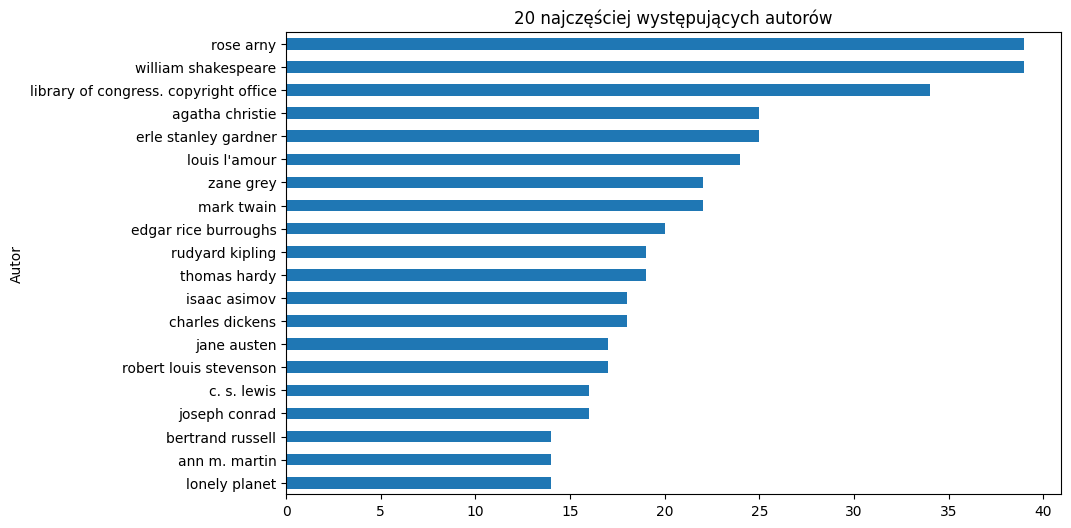

In [ ]:
top_authors_df.sort_values("Liczba książek").plot(
    x="Autor",
    y="Liczba książek",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    title="20 najczęściej występujących autorów"
)

- __Najrzadziej występujący autorzy__


In [ ]:
author_counts = Counter(all_authors)
least_common_authors = author_counts.most_common()[-20:]

least_common_authors_df = pd.DataFrame(
    least_common_authors,
    columns=["Autor", "Liczba książek"]
)

display(least_common_authors_df)

,Autor,Liczba książek
0,travis walton,1
1,natalie norton,1
2,mike bayer,1
3,robert dugoni,1
4,bruce averill,1
5,patricia eldredge,1
6,archibald joseph cronin,1
7,john gapper,1
8,nicholas denton,1
9,williston walker,1


In [ ]:
authors_with_one_book = sum(1 for count in author_counts.values() if count == 1)
print(f"Liczba autorów występujących tylko przy jednej książce: {authors_with_one_book}")

percentage = authors_with_one_book / len(author_counts) * 100
print(f"Odsetek autorów występujących tylko przy jednej książce: {percentage:.2f}%")

Liczba autorów występujących tylko przy jednej książce: 31332
Odsetek autorów występujących tylko przy jednej książce: 88.00%


- __Liczba autorów przypadających na jedną książkę__

In [ ]:
authors_per_book = books_raw_df["authors"].dropna().apply(lambda x: len(ast.literal_eval(x)))

In [ ]:
print(f"Średnia liczba autorów na książkę: {authors_per_book.mean():.2f}")
print(f"Mediana: {authors_per_book.median():.0f}")
print(f"Minimalna liczba autorów: {authors_per_book.min()}")
print(f"Maksymalna liczba autorów: {authors_per_book.max()}")

Średnia liczba autorów na książkę: 1.27
Mediana: 1
Minimalna liczba autorów: 1
Maksymalna liczba autorów: 43


In [ ]:
authors_distribution = authors_per_book.value_counts().sort_index()

display(authors_distribution.rename_axis("Liczba autorów").reset_index(name="Liczba książek"))

,Liczba autorów,Liczba książek
0,1,27297
1,2,4958
2,3,1155
3,4,282
4,5,84
5,6,31
6,7,19
7,8,9
8,9,5
9,10,3


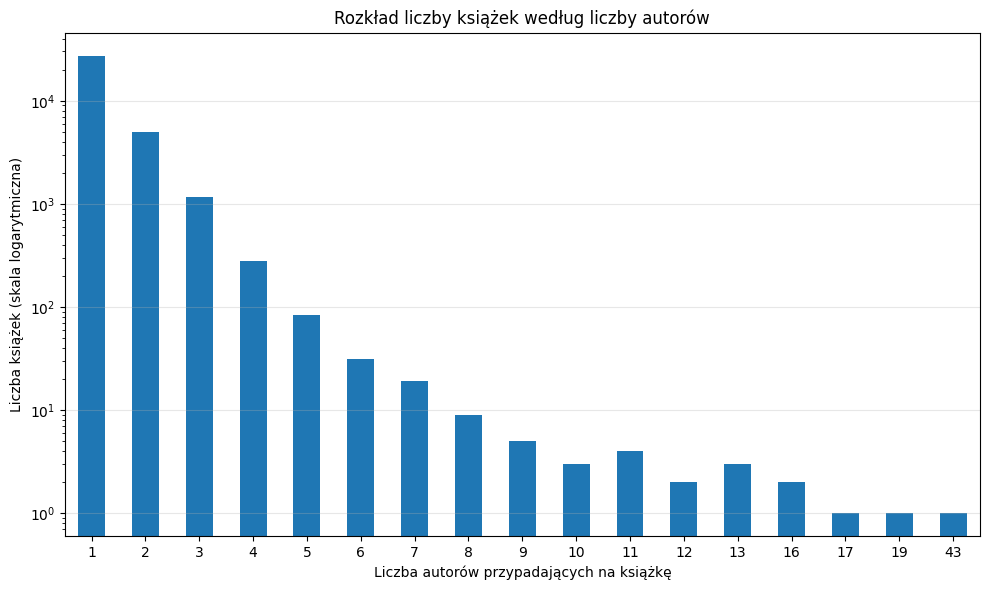

In [ ]:
import matplotlib.pyplot as plt

authors_distribution.plot(
    kind="bar",
    figsize=(10, 6),
)
plt.yscale("log")
plt.title("Rozkład liczby książek według liczby autorów")
plt.xlabel("Liczba autorów przypadających na książkę")
plt.ylabel("Liczba książek (skala logarytmiczna)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

__Książka z 43 autorami:__

In [ ]:
books_raw_df[
    books_raw_df["authors"].apply(
        lambda x: len(ast.literal_eval(x)) if pd.notna(x) else 0
    ) == 43
][["Title", "authors"]]

,Title,authors
25082,Deep Type,"['Arnold P. Pipilen', 'Carl Marlow McKinney', ..."


__Komentarz:__

W zbiorze odnotowano 35 605 unikalnych zapisów autorów. Najczęściej występującymi autorami są William Shakespeare i Rose Arny – każde z nich przypisano do 39 książek.  W zestawieniu znalazły się także wpisy dotyczące instytucji i organizacji, np. Library of Congress. Copyright Office, co wskazuje, że kolumna authors nie zawiera wyłącznie nazwisk pojedynczych osób.

Warto również zauważyć, że aż 31 332 autorów (88% wszystkich unikalnych zapisów) występuje tylko przy jednej książce. Oznacza to, że jedynie niewielka część autorów pojawia się w zbiorze przy większej liczbie publikacji.

Analiza liczby autorów przypadających na jedną książkę wykazała, że najczęściej książki mają jednego autora. Średnia wynosi 1,27 autora na książkę, natomiast mediana wynosi 1.

W zbiorze występuje również książka przypisana do aż 43 autorów. Jest to nietypowa wartość, dlatego warto zwrócić uwagę na takie rekordy podczas dalszej analizy danych.

Warto także pamiętać, że liczba unikalnych autorów odnosi się do różnych zapisów ich nazw, a niekoniecznie do różnych osób. Różne sposoby zapisu tego samego autora mogą być traktowane jako odrębne pozycje.

#### __2.3.2 Analiza kategorii__

Zamiana tekstowych list na listy Pythona

In [ ]:
categories_lists = books_raw_df['categories'].dropna().apply(ast.literal_eval)

- __Liczba unikalnych kategorii__

In [ ]:
all_categories = [
    category.strip().lower()
    for categories in categories_lists
    for category in categories
    if isinstance(category, str) and category.strip()
]

unique_categories = set(all_categories)

In [ ]:
print(f"Liczba unikalnych kategorii: {len(unique_categories)}")

Liczba unikalnych kategorii: 3573


__Komentarz:__

W analizowanym zbiorze obejmującym 36 053 książki odnotowano 3 573 unikalne kategorie, co oznacza, że dane zawierają dużą różnorodność tematyczną publikacji.

- __Liczba kategorii przypadających na jedną książkę__

In [ ]:
categories_per_book = categories_lists.apply(len)
categories_distribution = categories_per_book.value_counts().sort_index()

display(
    categories_distribution.rename_axis("Liczba kategorii").reset_index(name="Liczba książek")
)

,Liczba kategorii,Liczba książek
0,1,31975


__Komentarz:__

Analiza wykazała, że wszystkie książki posiadające uzupełnioną kolumnę `categories` mają przypisaną dokładnie jedną kategorię. Nie zaobserwowano przypadków, w których pojedyncza książka byłaby przypisana do kilku kategorii jednocześnie.

- __Najczęściej występujące kategorie__



In [ ]:
from collections import Counter

categories_counts = Counter(all_categories)

top_categories = categories_counts.most_common(20)

top_categories_df = pd.DataFrame(
    top_categories,
    columns=["Kategoria", "Liczba książek"]
)

display(top_categories_df)

,Kategoria,Liczba książek
0,fiction,4413
1,history,1781
2,religion,1770
3,juvenile fiction,1197
4,biography & autobiography,1164
5,business & economics,1085
6,computers,917
7,social science,703
8,juvenile nonfiction,595
9,education,529


<Axes: title={'center': '20 najczęściej występujących kategorii'}, ylabel='Kategoria'>

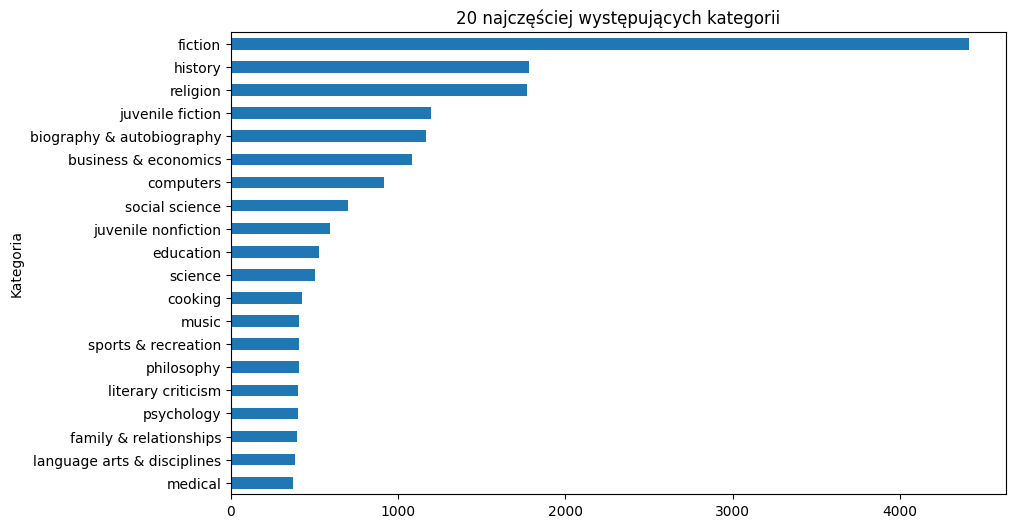

In [ ]:
top_categories_df.sort_values("Liczba książek").plot(
    x="Kategoria",
    y="Liczba książek",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    title="20 najczęściej występujących kategorii"
)

__Komentarz:__

Jak widać, najczęściej występującą kategorią jest *fiction* (4413 książek). Na kolejnych miejscach znajdują się *history* (1781 książek) oraz *religion* (1770 książek). W zestawieniu można zauważyć zarówno ogólne określenia kategorii, takie jak *fiction*, *history* czy *science*, jak i bardziej szczegółowe, np. *juvenile fiction* czy *juvenile nonfiction*. Oznacza to, że kategorie różnią się poziomem szczegółowości – niektóre określają szeroki obszar tematyczny, a inne konkretny rodzaj publikacji lub grupę odbiorców.

- __Najrzadziej występujące kategorie__

In [ ]:
categories_counts = Counter(all_categories)
least_common_categories = categories_counts.most_common()[-20:]

least_common_categories_df = pd.DataFrame(
    least_common_categories,
    columns=["Kategoria", "Liczba książek"]
)

display(least_common_categories_df)


,Kategoria,Liczba książek
0,"fantastic fiction, cuban",1
1,environmental protection,1
2,"dissertations, academic",1
3,toy industry,1
4,counterculture,1
5,jeopardy! (television program),1
6,italian fiction,1
7,"chinatown (london, england)",1
8,army life,1
9,aphrodite (greek deity),1


In [ ]:
categories_with_one_book = sum(1 for count in categories_counts.values() if count == 1)
print(f"Liczba kategorii występujących tylko przy jednej książce: {categories_with_one_book}")

percentage = categories_with_one_book / len(categories_counts) * 100
print(f"Odsetek kategorii występujących tylko przy jednej książce: {percentage:.2f}%")

Liczba kategorii występujących tylko przy jednej książce: 2488
Odsetek kategorii występujących tylko przy jednej książce: 69.63%


__Komentarz:__

Aż 2488 kategorii (69,63% wszystkich unikalnych kategorii) przypisano tylko do jednej książki. Wśród nich znajdują się bardzo szczegółowe określenia, np. *fantastic fiction, cuban*, *jeopardy! (television program)* czy *aphrodite (greek deity)*. Wskazuje to, że zbiór zawiera wiele niszowych kategorii, które dotyczą konkretnych zagadnień, miejsc, postaci lub wydarzeń i występują znacznie rzadziej niż kategorie ogólne.

### __2.4 Analiza recenzji oraz ocen__

Wykres sprawdzający rozrzut ocen

,Liczba recenzji,Udział [%]
review/score,,
1.0,35005,7.00
2.0,25687,5.14
3.0,42137,8.43
4.0,96841,19.37
5.0,300330,60.07


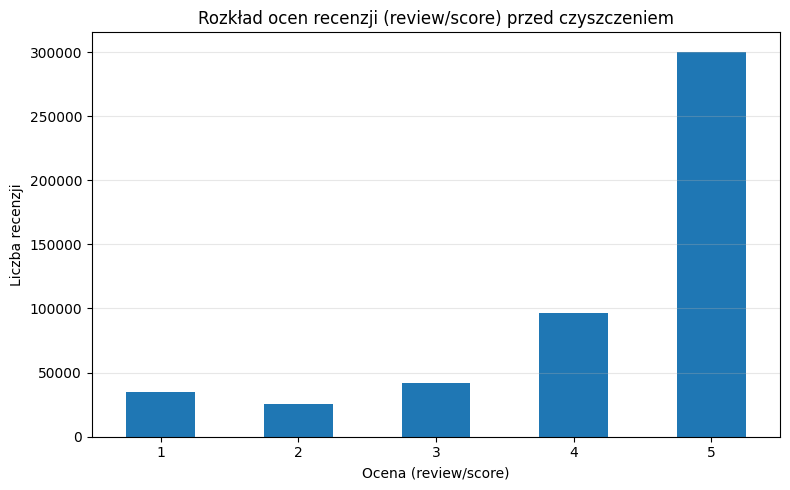

In [ ]:
import matplotlib.pyplot as plt

score_counts = reviews_raw_df["review/score"].value_counts().sort_index()
score_percentages = (reviews_raw_df["review/score"].value_counts(normalize=True).sort_index()*100).round(2)

score_summary = pd.DataFrame({
"Liczba recenzji": score_counts,
"Udział [%]": score_percentages
})

display(score_summary)

ax = score_counts.plot(
	kind = "bar",
	figsize = (8, 5),
	legend = False,
	title = "Rozkład ocen recenzji (review/score) przed czyszczeniem"
)

ax.set_xlabel("Ocena (review/score)")
ax.set_ylabel("Liczba recenzji")
ax.set_xticklabels([str(int(x)) if float(x).is_integer() else str(x) for x in score_counts.index], rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Komentarz:**

W zbiorze recenzji dominują wysokie oceny (głównie 5.0).

### __2.5 Wnioski__


Przeprowadzona analiza wstępna pozwoliła poznać strukturę zbiorów danych, ich zawartość oraz zidentyfikować problemy, które mogą mieć znaczenie na dalszych etapach projektu.



__Najważniejsze obserwacje:__
- __Wielkość zbiorów:__ zbiór książek (books_raw_df) zawiera 36 053 rekordy, natomiast zbiór recenzji (reviews_raw_df) obejmuje 500 000 rekordów. Należy pamiętać, że wykorzystano jedynie pierwsze 500 000 recenzji z oryginalnego zbioru.
- __Brakujące wartości:__ w zbiorze książek najwięcej braków występuje w kolumnach `ratingsCount`, `publisher` i `description`. W zbiorze recenzji największy problem dotyczy kolumny `Price`, w której brakuje większości wartości.
- __Duplikaty:__ w zbiorze książek wykryto 1028 powtarzających się tytułów. W zbiorze recenzji znaleziono 1764 identyczne rekordy.
- __Poprawność i spójność danych:__ sprawdzone oceny recenzji mieszczą się w oczekiwanym zakresie od 1 do 5. Nie stwierdzono również pustych tytułów książek ani pustych treści recenzji
- __Analiza kolumny `authors` ze zbioru książek:__ w zbiorze występuje 35 605 unikalnych zapisów autorów. Zdecydowana większość z nich (88%) pojawia się tylko przy jednej książce. Zauważono również wpisy dotyczące instytucji i organizacji, a nie wyłącznie pojedynczych osób.
- __Analiza kolumny `categories` ze zbioru książek:__ - odnotowano 3573 unikalne kategorie. Najczęściej występuje kategoria *fiction*, natomiast prawie 70% kategorii przypisano tylko do jednej książki. Kategorie różnią się poziomem szczegółowości.

Podsumowując, zbiory zawierają informacje przydatne do realizacji projektu systemu rekomendacji książek oraz analizy sentymentu recenzji. Jednocześnie wymagają dalszego przygotowania, przede wszystkim w zakresie brakujących wartości, duplikatów, ujednolicenia zapisów tekstowych oraz weryfikacji poprawności wybranych kolumn. Zidentyfikowane problemy zostaną uwzględnione na kolejnym etapie, czyli podczas czyszczenia i przygotowania danych.

## __3. Czyszczenie danych__

In [ ]:
reviews_cleaned_df, books_cleaned_df = clean_data(
    reviews_raw_df,
    books_raw_df,
    lemmatize=False
)

Na podstawie zidentyfikowanych w poprzedniej części problemów związanych z jakością i spójnością danych przeprowadzono proces ich czyszczenia i przygotowania do dalszej analizy. W przypadku obu zbiorów ograniczono liczbę wykorzystywanych kolumn do tych, które są istotne z punktu widzenia projektu.

__W zbiorze recenzji:__
- Pozostawiono kolumny `Title`, `review/score` oraz `review/text`.
- Usunięto rekordy zawierające brakujące wartości w którejkolwiek z tych kolumn, ponieważ kompletność tych informacji jest istotna dla dalszego przetwarzania i analizy sentymentu.
- Nazwy kolumn ujednolicono, zastępując ukośniki znakami podkreślenia.
- Przygotowano tekst recenzji: zamieniono encje HTML na odpowiadające im znaki, usunięto znaczniki HTML i adresy URL, zamieniono wszystkie litery na małe, usunięto znaki specjalne i interpunkcyjne (z wyjątkiem apostrofów), a także zastąpiono wielokrotne spacje pojedynczymi. Na końcu usunięto recenzje, których treść po oczyszczeniu była pusta.
- Utworzono również pomocniczą kolumnę `title_key`, zawierającą tytuł książki zapisany małymi literami z zastosowaniem konwencji snake_case, która ułatwia późniejsze łączenie zbiorów danych.

__W zbiorze książek:__
- Pozostawiono  kolumny `Title`, `authors`, `categories` oraz `description`.
- Usunięto rekordy zawierające brakujące wartości w tych kolumnach.
- Nazwy kolumn ujednolicono do małych liter.
- Wartości w kolumnach `authors` i `categories` przekształcono z tekstowej reprezentacji list na rzeczywiste listy Pythona.
- Nazwy kategorii dodatkowo zapisano małymi literami i usunięto zbędne spacje na początku oraz końcu tekstu.
- Utworzono również pomocniczą kolumnę `title_key`, zawierającą tytuł książki zapisany małymi literami z zastosowaniem konwencji snake_case, która ułatwia późniejsze łączenie zbiorów danych.

Na końcu zresetowano indeksy obu zbiorów, aby zapewnić ich uporządkowaną numerację.

## __4. Analiza danych po przetworzeniu__

### __4.1 Ogólna charakterystyka zbiorów danych__

#### __4.1.1 Rozmiar zbiorów danych__

In [ ]:
print(f"Liczba książek: {books_cleaned_df.shape[0]}")
print(f"Liczba recenzji: {reviews_cleaned_df.shape[0]}")

print(f"\nWymiary zbioru książek: {books_cleaned_df.shape}")
print(f"Wymiary zbioru recenzji: {reviews_cleaned_df.shape}")

Liczba książek: 25340
Liczba recenzji: 499992

Wymiary zbioru książek: (25340, 5)
Wymiary zbioru recenzji: (499992, 4)


__Komentarz:__

Po przeprowadzeniu czyszczenia liczba rekordów w zbiorze książek zmniejszyła się z __36 053__ do __25 340__, co oznacza usunięcie __10 713__ rekordów (około __29,7%__). Zmiana wynika z zastosowanych operacji czyszczenia i filtrowania danych.

W przypadku zbioru recenzji liczba rekordów zmniejszyła się jedynie z __500 000__ do __499 992__, czyli usunięto __8__ rekordów.


#### __4.1.2 Opis kolumn__

In [ ]:
print("Zbiór książek:")
print(books_cleaned_df.columns.tolist())

print("\nZbiór recenzji:")
print(reviews_cleaned_df.columns.tolist())

Zbiór książek:
['title', 'authors', 'categories', 'description', 'title_key']

Zbiór recenzji:
['id', 'title', 'review_score', 'review_text']


__Opisy kolumn finalnych wersji zbiorów danych:__

__books_df__
-  `title` -  Tytuł książki
- `authors` - Lista autorów
- `categories` - Lista kategorii
- `description` - Opis książki
- `title_key` - Znormalizowany tytuł książki, wykorzystywany do dopasowywania rekordów między zbiorami danych

__reviews_df__
- `title_key` - Znormalizowany tytuł książki, wykorzystywany do dopasowywania rekordów między zbiorami danych
- `review_score` - Ocena książki wystawiona przez użytkownika (w skali 1-5)
-  `reviews_text` - Tekst recenzji


#### __4.2.3 Podgląd przykładowych rekordów__

__a) Zbiór książek__

In [ ]:
books_cleaned_df.head()

,title,authors,categories,description,title_key
0,Dr. Seuss: American Icon,[Philip Nel],[biography & autobiography],Philip Nel takes a fascinating look into the k...,dr. seuss: american icon
1,Wonderful Worship in Smaller Churches,[David R. Ray],[religion],This resource includes twelve principles in un...,wonderful worship in smaller churches
2,Whispers of the Wicked Saints,[Veronica Haddon],[fiction],Julia Thomas finds her life spinning out of co...,whispers of the wicked saints
3,The Church of Christ: A Biblical Ecclesiology ...,[Everett Ferguson],[religion],In The Church of Christ: A Biblical Ecclesiolo...,the church of christ: a biblical ecclesiology ...
4,Saint Hyacinth of Poland,[Mary Fabyan Windeatt],[biography & autobiography],The story for children 10 and up of St. Hyacin...,saint hyacinth of poland


__b) Zbiór recenzji__

In [ ]:
reviews_cleaned_df.head()

,id,title,review_score,review_text
0,1882931173,Its Only Art If Its Well Hung!,4.0,this is only for julie strain fans it's a coll...
1,0826414346,Dr. Seuss: American Icon,5.0,i don't care much for dr seuss but after readi...
2,0826414346,Dr. Seuss: American Icon,5.0,if people become the books they read and if th...
3,0826414346,Dr. Seuss: American Icon,4.0,theodore seuss geisel 1904 1991 aka dr seuss w...
4,0826414346,Dr. Seuss: American Icon,4.0,philip nel dr seuss american iconthis is basic...


,liczba rekordów przed,Liczba rekordów po,Różnica (usunięte),Liczba kolumn przed,Liczba kolumn po
Książki (books),36053,25340,10713,10,5
Recenzje (reviews),500000,499992,8,10,4


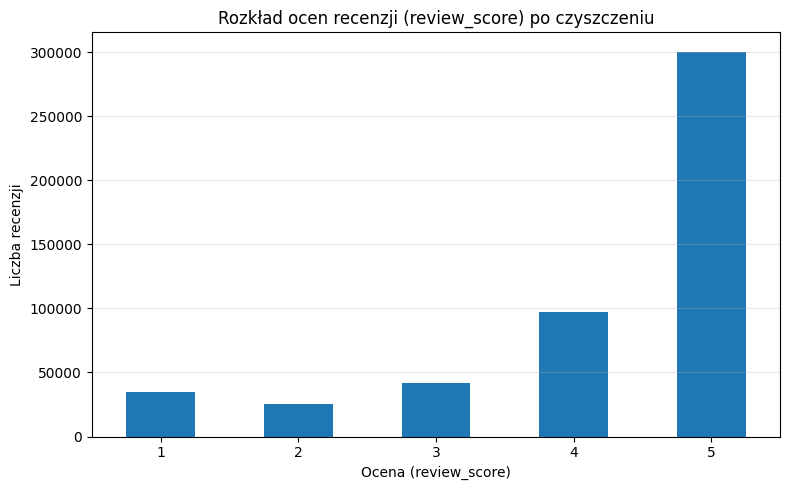

In [ ]:
summary_comparison = pd.DataFrame(
{
  "liczba rekordów przed": [len(books_raw_df), len(reviews_raw_df)],
  "Liczba rekordów po": [len(books_cleaned_df), len(reviews_cleaned_df)],
  "Różnica (usunięte)": [
    len(books_raw_df) - len(books_cleaned_df),
    len(reviews_raw_df) - len(reviews_cleaned_df),
  ],
  "Liczba kolumn przed": [books_raw_df.shape[1], reviews_raw_df.shape[1]],
  "Liczba kolumn po": [books_cleaned_df.shape[1], reviews_cleaned_df.shape[1]],
}, index = ["Książki (books)", "Recenzje (reviews)"])

display(summary_comparison)

cleaned_score_counts = reviews_cleaned_df["review_score"].value_counts().sort_index()

ax = cleaned_score_counts.plot(
	kind = "bar",
	figsize = (8, 5),
	legend = False,
	title = "Rozkład ocen recenzji (review_score) po czyszczeniu"
)

ax.set_xlabel("Ocena (review_score)")
ax.set_ylabel("Liczba recenzji")
ax.set_xticklabels([str(int(x)) if float(x).is_integer() else str(x) for x in cleaned_score_counts.index], rotation = 0)
plt.grid(axis="y", alpha = 0.3)
plt.tight_layout()
plt.show()

**Komentarz:**

Zestawienie podsumowuje zmianę liczby rekordów i kolumn po uruchomieniu funkcji `clean_data`. Rozkład ocen (`review_score`) po czyszczeniu zachowuje proporcje zbioru wejściowego po odrzuceniu rekordów niekompletnych lub pustych po czyszczeniu tekstu.

### __4.2 ...__